<a href="https://colab.research.google.com/github/navyashreenavy/Airlines-Management/blob/main/DL_Model_Training_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!

Dataset Information
Training samples: 1400
Validation samples: 300
Testing samples: 300

Model Architecture: [32, 16]

Optimizer: SGD
Regularization: None
Training completed!
Test Loss: 0.155
Test Accuracy: 94.67 %

Optimizer: SGD
Regularization: L1
Training completed!
Test Loss: 0.1998
Test Accuracy: 94.67 %

Optimizer: SGD
Regularization: L2
Training completed!
Test Loss: 0.181
Test Accuracy: 94.67 %

Optimizer: SGD
Regularization: Dropout
Training completed!
Test Loss: 0.1472
Test Accuracy: 94.33 %

Optimizer: Adam
Regularization: None
Training completed!
Test Loss: 0.1616
Test Accuracy: 93.67 %

Optimizer: Adam
Regularization: L1
Training completed!
Test Loss: 0.1832
Test Accuracy: 93.67 %

Optimizer: Adam
Regularization: L2
Training completed!
Test Loss: 0.179
Test Accuracy: 93.67 %

Optimizer: Adam
Regularization: Dropout
Training completed!
Test Loss: 0.152
Test Accuracy: 94.67 %

Optimizer: RMSprop
Regularization: None
Training completed!
Test 

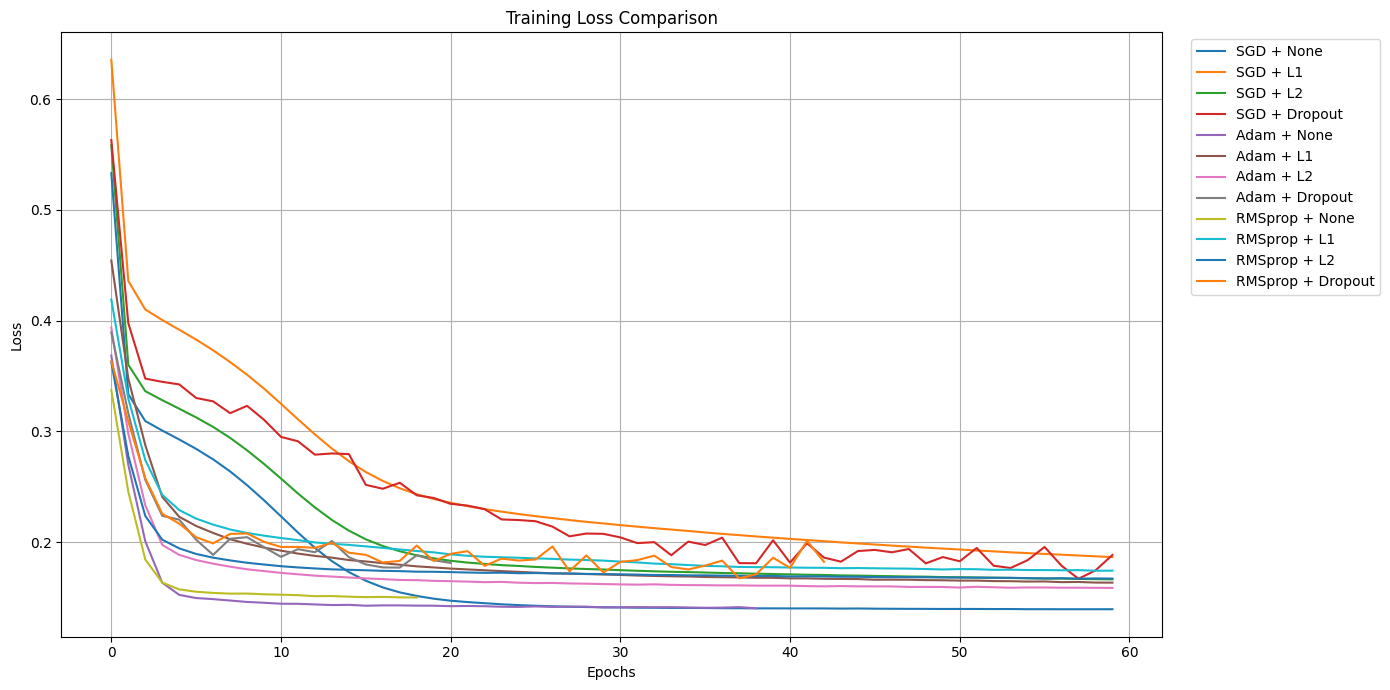

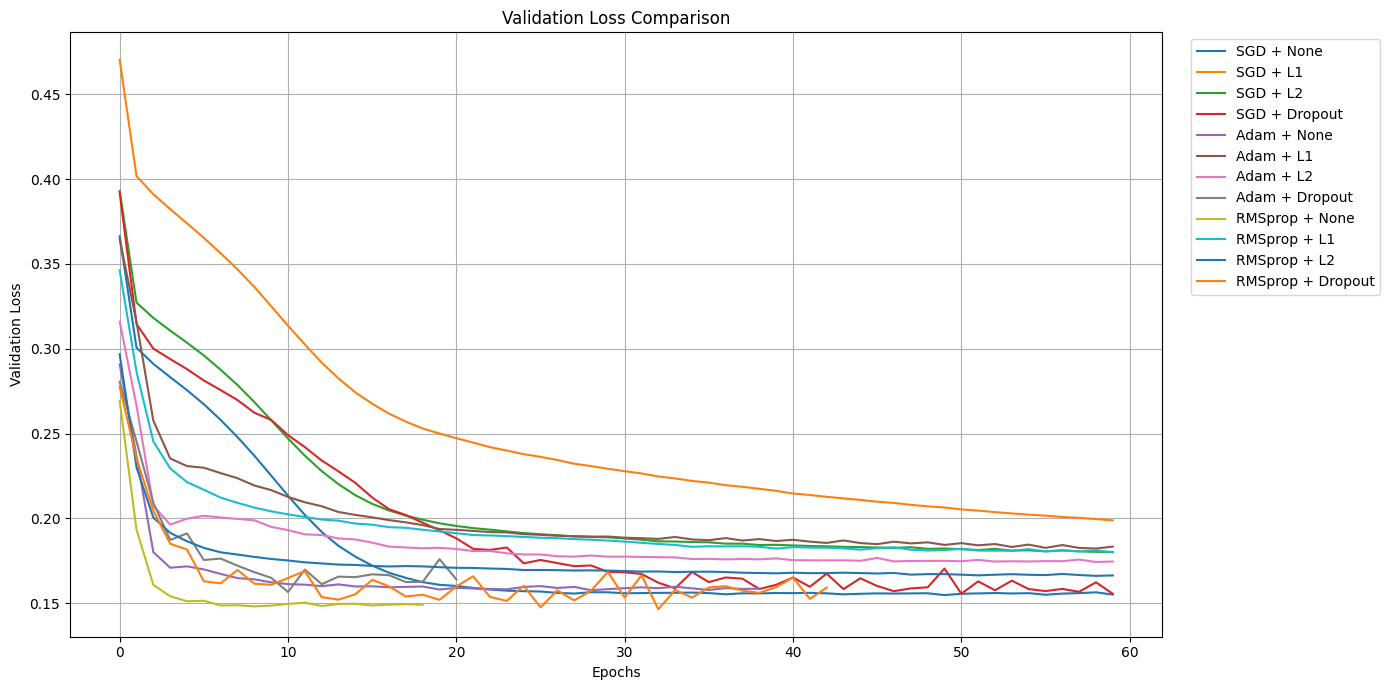

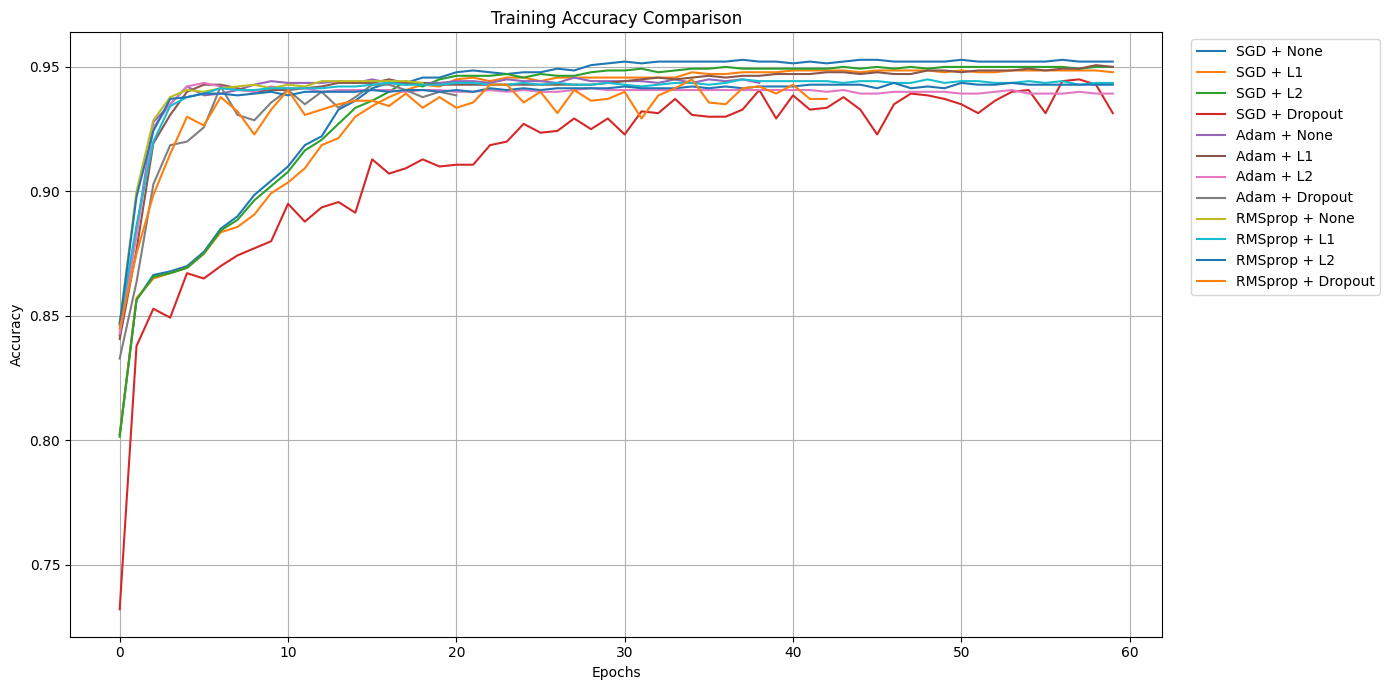

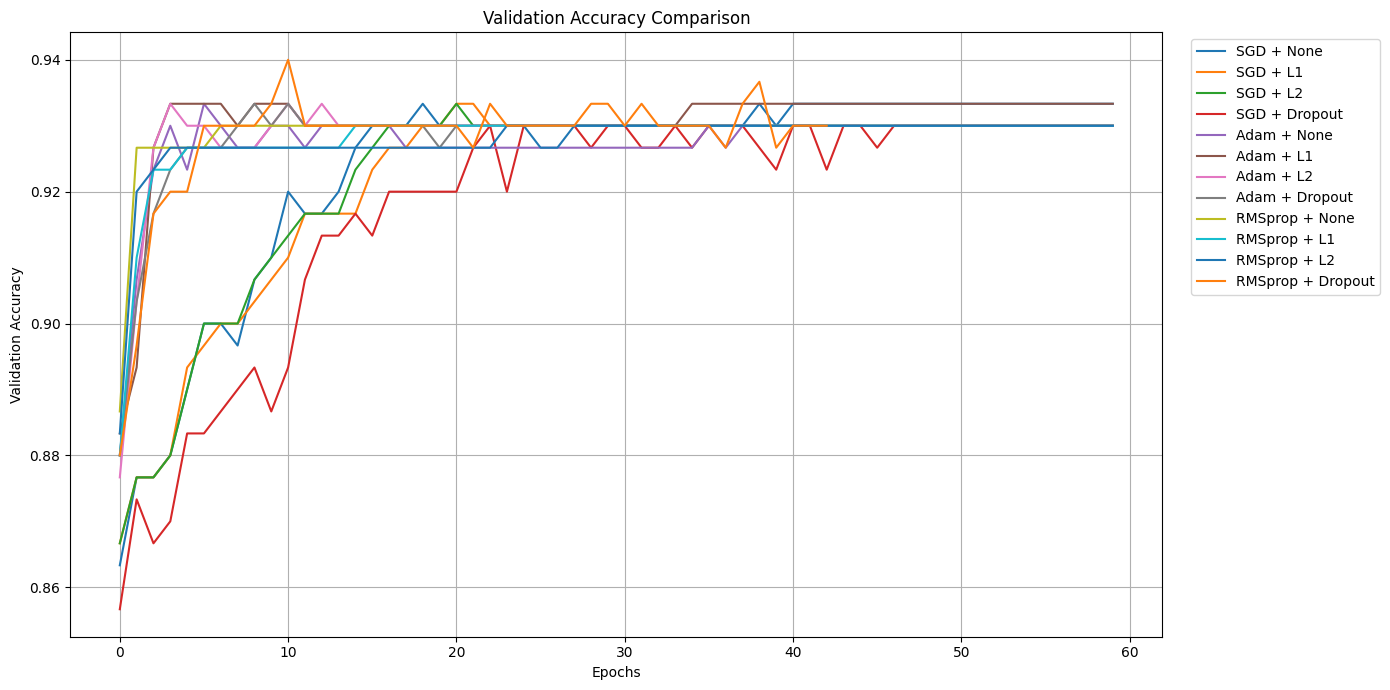

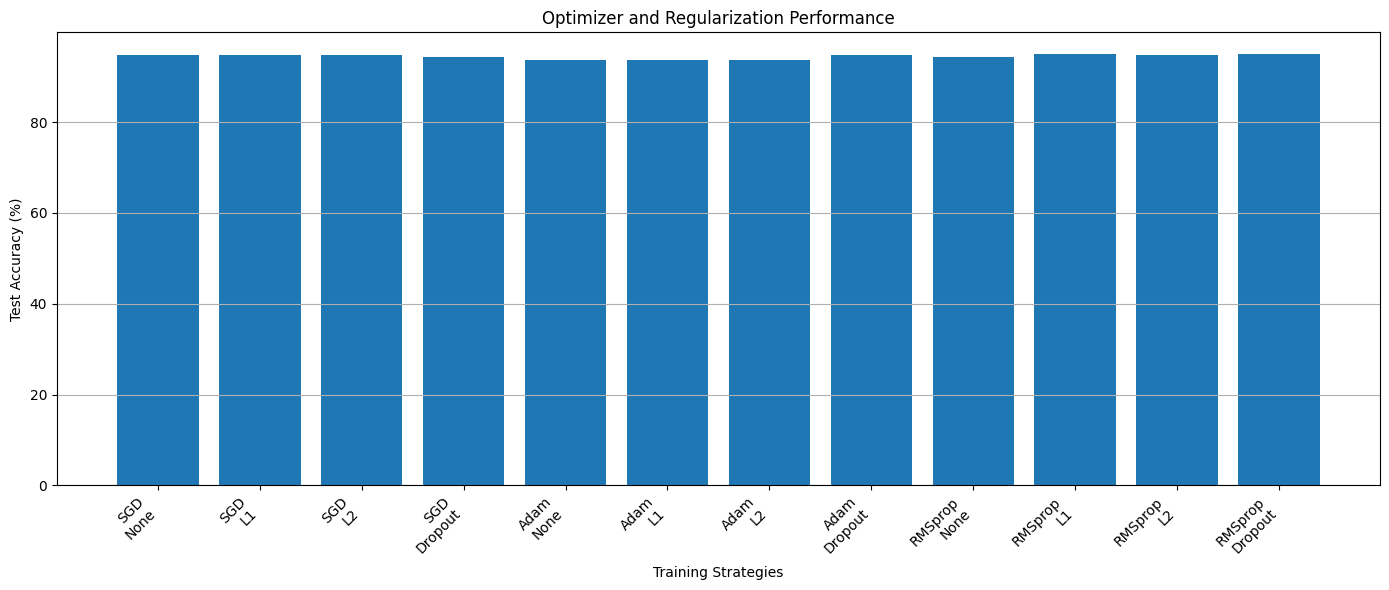


========== BEST MODEL ==========
Optimizer: RMSprop
Regularization: L1
Test Accuracy: 95.0 %
Test Loss: 0.178

TRAINING STRATEGY SIMULATOR COMPLETED
All optimizers tested successfully.
All regularization methods tested successfully.
Loss curves generated successfully.
Accuracy curves generated successfully.
Model comparison completed successfully.


In [1]:
# ============================================================
# MODULE PROJECT: TRAINING STRATEGY AND OPTIMIZATION SIMULATOR
# ============================================================

# Step 1: Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

print("Libraries imported successfully!")


# Step 2: Generate Dataset

X, y = make_moons(
    n_samples=2000,
    noise=0.25,
    random_state=42
)

y = y.reshape(-1, 1)

# Split into training, validation and testing data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

# Normalize input data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("\nDataset Information")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


# Step 3: Configurable Model Architecture

HIDDEN_LAYERS = [32, 16]
EPOCHS = 60
BATCH_SIZE = 32
LEARNING_RATE = 0.01
DROPOUT_RATE = 0.3
REGULARIZATION_RATE = 0.001

print("\nModel Architecture:", HIDDEN_LAYERS)


# Step 4: Select Optimizers

def get_optimizer(name):

    if name == "SGD":
        return tf.keras.optimizers.SGD(
            learning_rate=LEARNING_RATE,
            momentum=0.9
        )

    elif name == "Adam":
        return tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        )

    elif name == "RMSprop":
        return tf.keras.optimizers.RMSprop(
            learning_rate=LEARNING_RATE
        )


# Step 5: Apply Regularization Methods

def get_regularizer(name):

    if name == "L1":
        return l1(REGULARIZATION_RATE)

    elif name == "L2":
        return l2(REGULARIZATION_RATE)

    else:
        return None


# Step 6: Build Neural Network Model

def build_model(regularization):

    model = Sequential()

    model.add(Input(shape=(X_train.shape[1],)))

    reg = get_regularizer(regularization)

    for units in HIDDEN_LAYERS:

        model.add(Dense(
            units,
            activation="relu",
            kernel_regularizer=reg
        ))

        if regularization == "Dropout":
            model.add(Dropout(DROPOUT_RATE))

    model.add(Dense(1, activation="sigmoid"))

    return model


# Step 7: Define Training Strategies

optimizers = ["SGD", "Adam", "RMSprop"]

regularization_methods = [
    "None",
    "L1",
    "L2",
    "Dropout"
]

results = []
histories = {}


# Step 8: Train Models Using Different Strategies

for optimizer_name in optimizers:

    for reg_name in regularization_methods:

        print("\n================================")
        print("Optimizer:", optimizer_name)
        print("Regularization:", reg_name)
        print("================================")

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(42)

        model = build_model(reg_name)

        model.compile(
            optimizer=get_optimizer(optimizer_name),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        history = model.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[early_stop],
            verbose=0
        )

        # Evaluate model on test data
        test_loss, test_accuracy = model.evaluate(
            X_test, y_test, verbose=0
        )

        histories[(optimizer_name, reg_name)] = history.history

        results.append({
            "Optimizer": optimizer_name,
            "Regularization": reg_name,
            "Epochs": len(history.history["loss"]),
            "Test Loss": test_loss,
            "Test Accuracy": test_accuracy * 100
        })

        print("Training completed!")
        print("Test Loss:", round(test_loss, 4))
        print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


# Step 9: Display Performance Comparison

results_df = pd.DataFrame(results)

print("\n========== MODEL PERFORMANCE COMPARISON ==========")

print(
    results_df.sort_values(
        by="Test Accuracy",
        ascending=False
    ).to_string(index=False)
)


# Step 10: Visualize Loss Curves

plt.figure(figsize=(14, 7))

for key, history in histories.items():

    label = key[0] + " + " + key[1]

    plt.plot(
        history["loss"],
        label=label
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


# Step 11: Visualize Validation Loss Curves

plt.figure(figsize=(14, 7))

for key, history in histories.items():

    label = key[0] + " + " + key[1]

    plt.plot(
        history["val_loss"],
        label=label
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


# Step 12: Visualize Accuracy Curves

plt.figure(figsize=(14, 7))

for key, history in histories.items():

    label = key[0] + " + " + key[1]

    plt.plot(
        history["accuracy"],
        label=label
    )

plt.title("Training Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


# Step 13: Visualize Validation Accuracy Curves

plt.figure(figsize=(14, 7))

for key, history in histories.items():

    label = key[0] + " + " + key[1]

    plt.plot(
        history["val_accuracy"],
        label=label
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


# Step 14: Compare Final Test Accuracy

plt.figure(figsize=(14, 6))

labels = [
    row["Optimizer"] + "\n" + row["Regularization"]
    for row in results
]

accuracies = results_df["Test Accuracy"]

plt.bar(labels, accuracies)

plt.title("Optimizer and Regularization Performance")
plt.xlabel("Training Strategies")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# Step 15: Display Best Model Performance

best_model = results_df.loc[
    results_df["Test Accuracy"].idxmax()
]

print("\n========== BEST MODEL ==========")

print("Optimizer:", best_model["Optimizer"])
print("Regularization:", best_model["Regularization"])
print("Test Accuracy:",
      round(best_model["Test Accuracy"], 2), "%")
print("Test Loss:", round(best_model["Test Loss"], 4))


# Step 16: Final Result

print("\n======================================")
print("TRAINING STRATEGY SIMULATOR COMPLETED")
print("======================================")

print("All optimizers tested successfully.")
print("All regularization methods tested successfully.")
print("Loss curves generated successfully.")
print("Accuracy curves generated successfully.")
print("Model comparison completed successfully.")